<a href="https://colab.research.google.com/github/FardinLakdawala/prml-assigments/blob/main/Lab4_Bank_Marketing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 4 — Bank Marketing: EDA, Decision Tree and K-NN

**Dataset:** `bank-full.csv` — direct-marketing phone campaigns of a Portuguese bank (45,211 clients, 16 input features).
**Goal:** predict whether a client subscribes to a term deposit (`y` = yes / no).

**What this notebook does**

| Part | Task |
|---|---|
| 0 | Exploratory Data Analysis (EDA) |
| 1 | Random shuffle + 80:20 train–test split |
| 2 | Decision Tree Classifier |
| 3 | K-NN and Weighted K-NN, compared for K = 1, 3, 5 |
| 4 | Overall comparison and conclusions |

Every model is evaluated with **accuracy, precision, recall, F1-score and a confusion matrix**.
Data handling and plotting use pandas / numpy / matplotlib; all modelling and metrics come from **scikit-learn**.

In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

# --- scikit-learn Imports and Explanations ---
# train_test_split: Splits datasets into random train and test subsets.
# cross_val_score: Evaluates a score by cross-validation.
# StratifiedKFold: Provides train/test indices to split data in train/test sets, preserving class percentage.
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold

# ColumnTransformer: Applies transformers to columns of an array or pandas DataFrame.
from sklearn.compose import ColumnTransformer

# Pipeline: Sequentially chains multiple transforms and an estimator together.
from sklearn.pipeline import Pipeline

# StandardScaler: Standardizes features by removing the mean and scaling to unit variance.
# OneHotEncoder: Encodes categorical features as a one-hot numeric array.
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# DecisionTreeClassifier: A non-parametric supervised learning method used for classification.
from sklearn.tree import DecisionTreeClassifier

# KNeighborsClassifier: Classifier implementing the k-nearest neighbors vote.
from sklearn.neighbors import KNeighborsClassifier

# Performance metrics for model evaluation:
# accuracy_score: Computes subset accuracy.
# precision_score: Computes the precision (TP / (TP + FP)).
# recall_score: Computes the recall (TP / (TP + FN)).
# f1_score: Computes the F1 score, the harmonic mean of precision and recall.
# confusion_matrix: Computes confusion matrix to evaluate the accuracy of a classification.
# ConfusionMatrixDisplay: Confusion Matrix visualization.
# classification_report: Builds a text report showing the main classification metrics.
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

RANDOM_STATE = 42                     # makes the shuffle / split reproducible
pd.set_option("display.max_columns", 50)

---
## 0. Exploratory Data Analysis

### 0.1 Load the data
The file is **semicolon-separated**, so we pass `sep=";"`.

In [14]:
# Looks for the file next to the notebook, or inside the unzipped lab folder
candidates = [Path("bank-full.csv"), Path("Lab-4-20112026/bank-full.csv")]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("bank-full.csv not found - put it next to this notebook or edit `candidates`.")

df = pd.read_csv(DATA_PATH, sep=";")
print(f"Loaded {DATA_PATH}: {df.shape[0]:,} rows x {df.shape[1]} columns")
display(df.head())

Loaded bank-full.csv: 45,211 rows x 17 columns


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


### 0.2 Structure and data quality

In [15]:
df.info()
print("\nMissing values (total):", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB

Missing values (total): 0
Duplicate rows: 0


In [16]:
# Column groups (target 'y' is excluded from the categorical list)
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(exclude="number").columns.drop("y").tolist()
print("Numeric    :", num_cols)
print("Categorical:", cat_cols)

# There are no NaNs, but several columns use the label 'unknown' as a hidden missing value
unknown_pct = {c: (df[c] == "unknown").mean() * 100 for c in cat_cols if (df[c] == "unknown").any()}
print("\nShare of 'unknown' per column (%):")
display(pd.Series(unknown_pct, name="% unknown").round(2).sort_values(ascending=False).to_frame())

Numeric    : ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Share of 'unknown' per column (%):


,% unknown
poutcome,81.75
contact,28.80
education,4.11
job,0.64


### 0.3 Summary statistics

In [17]:
display(df[num_cols].describe().T.round(2))
display(df[cat_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.94,10.62,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.27,3044.77,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.81,8.32,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.16,257.53,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.76,3.10,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.20,100.13,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.58,2.30,0.0,0.0,0.0,0.0,275.0


,count,unique,top,freq
job,45211,12,blue-collar,9732
marital,45211,3,married,27214
education,45211,4,secondary,23202
default,45211,2,no,44396
housing,45211,2,yes,25130
loan,45211,2,no,37967
contact,45211,3,cellular,29285
month,45211,12,may,13766
poutcome,45211,4,unknown,36959


### 0.4 Target distribution
Class balance matters a lot here: it decides which metrics are meaningful.

     count  percent
y                  
no   39922     88.3
yes   5289     11.7


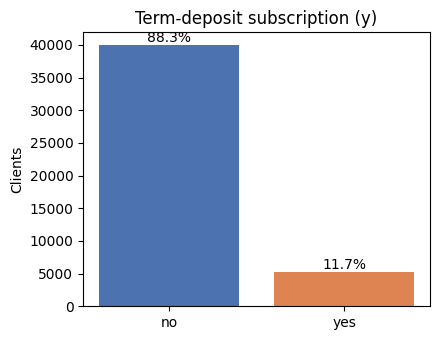

In [18]:
counts = df["y"].value_counts()
pct = df["y"].value_counts(normalize=True) * 100
print(pd.DataFrame({"count": counts, "percent": pct.round(2)}).to_string())

fig, ax = plt.subplots(figsize=(4.5, 3.5))
bars = ax.bar(counts.index, counts.values, color=["#4c72b0", "#dd8452"])
for b, p in zip(bars, pct[counts.index]):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{p:.1f}%", ha="center", va="bottom")
ax.set_title("Term-deposit subscription (y)")
ax.set_ylabel("Clients")
plt.tight_layout()
plt.show()

### 0.5 Numeric features
Histograms (clipped at the 99th percentile so the long tails don't squash the plot) and box plots split by the target.

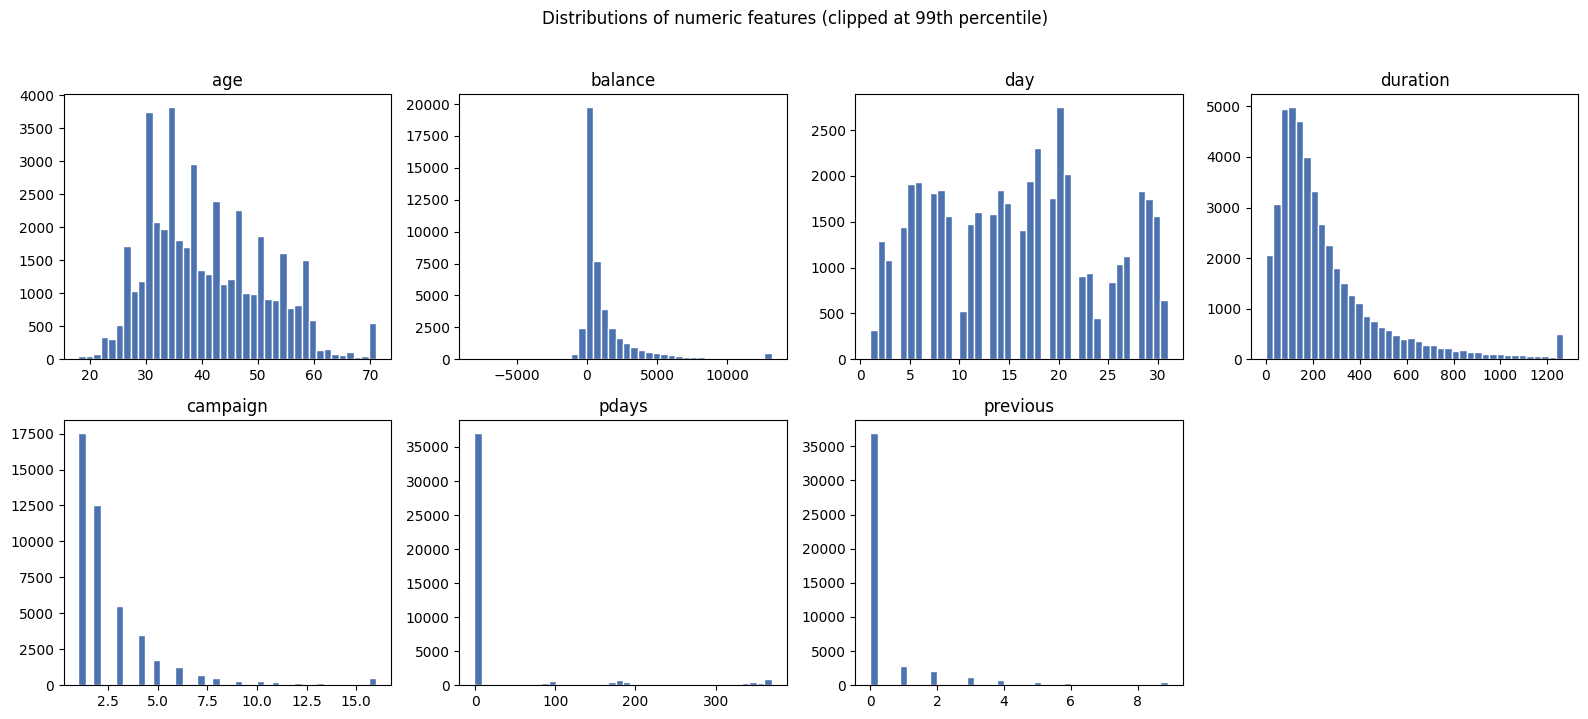

In [19]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), num_cols):
    ax.hist(df[c].clip(upper=df[c].quantile(0.99)), bins=40, color="#4c72b0", edgecolor="white")
    ax.set_title(c)
for ax in axes.ravel()[len(num_cols):]:
    ax.axis("off")
fig.suptitle("Distributions of numeric features (clipped at 99th percentile)", y=1.02)
plt.tight_layout()
plt.show()

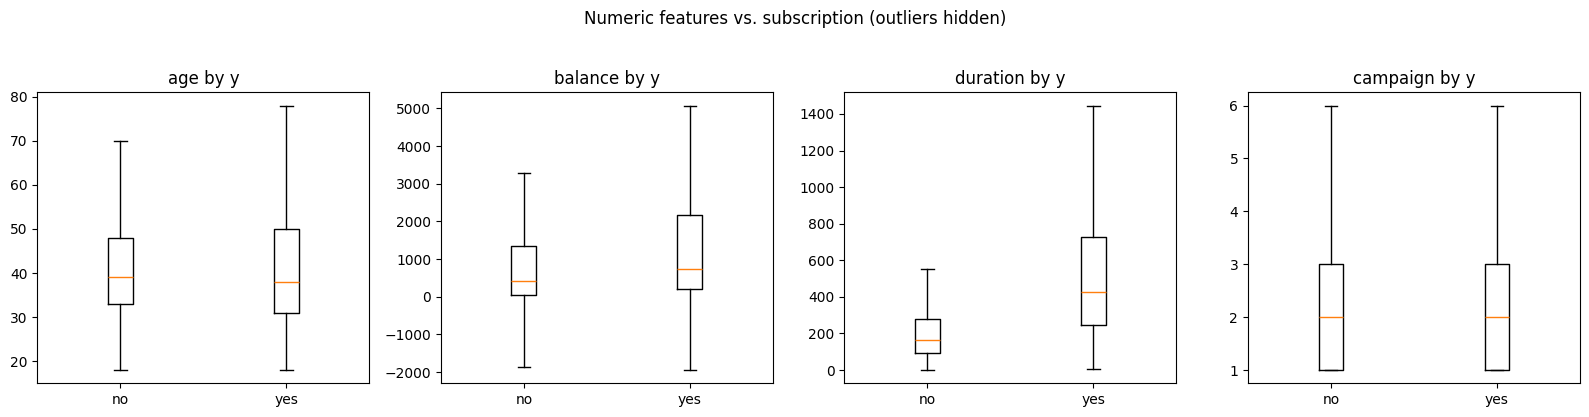

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, ["age", "balance", "duration", "campaign"]):
    ax.boxplot([df.loc[df["y"] == "no", c], df.loc[df["y"] == "yes", c]], showfliers=False)
    ax.set_xticklabels(["no", "yes"])
    ax.set_title(f"{c} by y")
fig.suptitle("Numeric features vs. subscription (outliers hidden)", y=1.03)
plt.tight_layout()
plt.show()

### 0.6 Categorical features
Subscription rate (% of clients with `y = yes`) in each category. The red dashed line is the overall rate.

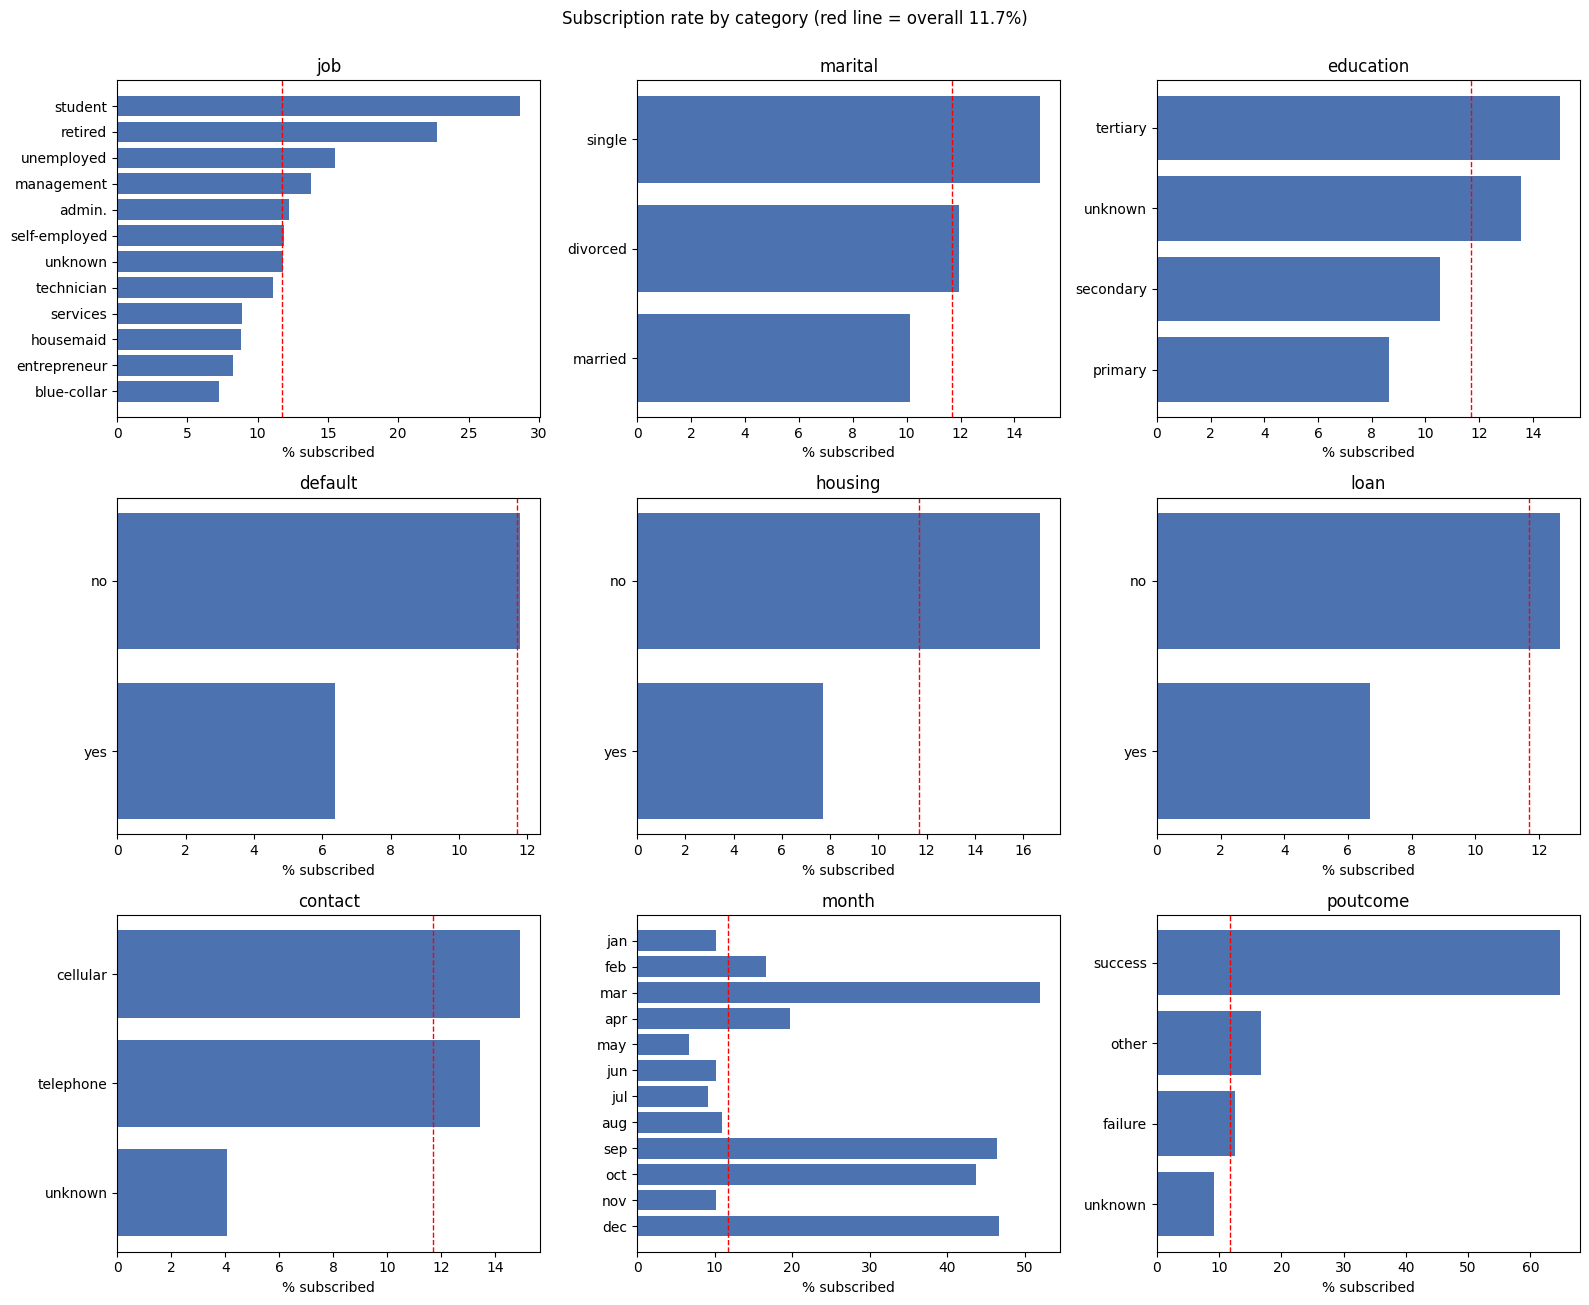

In [21]:
month_order = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
overall = (df["y"] == "yes").mean() * 100
plot_cats = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "poutcome"]

fig, axes = plt.subplots(3, 3, figsize=(16, 13))
for ax, c in zip(axes.ravel(), plot_cats):
    rate = (df["y"] == "yes").groupby(df[c]).mean() * 100
    rate = rate.reindex(month_order) if c == "month" else rate.sort_values()
    ax.barh(rate.index.astype(str), rate.values, color="#4c72b0")
    ax.axvline(overall, color="red", ls="--", lw=1)
    ax.set_title(c)
    ax.set_xlabel("% subscribed")
    if c == "month":
        ax.invert_yaxis()
fig.suptitle(f"Subscription rate by category (red line = overall {overall:.1f}%)", y=1.0)
plt.tight_layout()
plt.show()

### 0.7 Correlation between numeric features

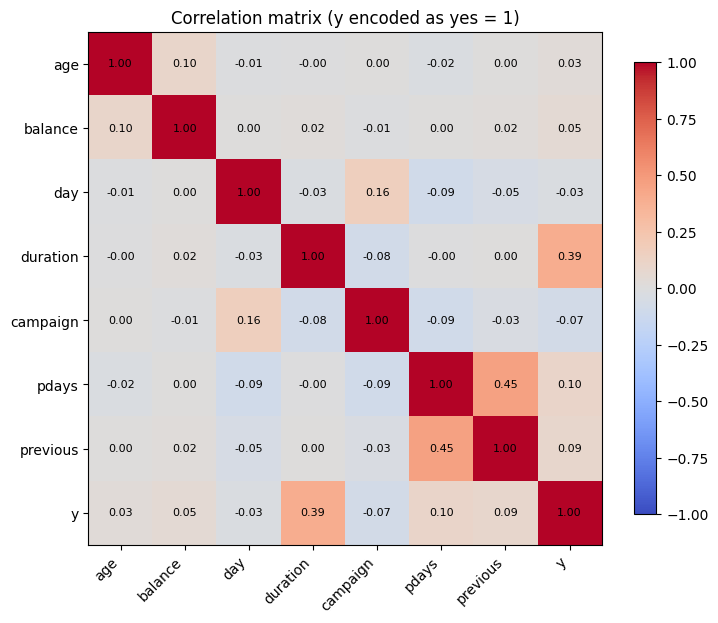

In [22]:
corr = df[num_cols].assign(y=(df["y"] == "yes").astype(int)).corr()

fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation matrix (y encoded as yes = 1)")
plt.tight_layout()
plt.show()

### 0.8 EDA — key observations

* **Strong class imbalance:** about 88% of clients said *no* and about 12% said *yes*. A model that always predicts "no" already reaches roughly 88% accuracy, so **accuracy alone is misleading** — precision, recall and F1 of the *yes* class are what really matter.
* **Clean but with hidden gaps:** there are no `NaN`s or duplicates, but `unknown` is used as a placeholder — about 82% of `poutcome`, 29% of `contact`, 4% of `education` and under 1% of `job`. We keep `unknown` as its own category.
* **`pdays = -1` is a special code** meaning "never contacted before" (about 82% of rows, identical to `previous = 0`), so `pdays` is not a normal numeric scale.
* **Skewed numerics with outliers:** `balance`, `duration`, `campaign`, `pdays` and `previous` have long right tails (e.g. balance reaches ~102,000 and is negative for some clients).
* **Who subscribes more:** students and retired clients, single clients, tertiary education, clients with *no* housing loan and *no* personal loan, and above all clients whose **previous campaign was a success** (about 65% subscribe). Some months (Mar, Sep, Oct, Dec) show very high rates but have few contacts.
* **`duration` is the strongest numeric signal** (correlation ≈ 0.39 with `y`). The dataset documentation warns that call duration is only known *after* the call, so it leaks the outcome and is meant for benchmarking. This notebook keeps it by default (see the switch in Part 1).
* **Scale differences matter:** `balance` is in the thousands while `campaign` is single-digit — distance-based K-NN will need **feature scaling**; decision trees will not.

---
## 1. Train–test split (random shuffle, 80:20)

* The target is encoded as `yes = 1`, `no = 0`, so **"yes" is the positive class** for precision / recall / F1.
* `train_test_split(..., shuffle=True)` randomly shuffles the rows before splitting; `test_size=0.20` gives the 80:20 split.
* `stratify=y` keeps the 88/12 class ratio the same in both parts (important with imbalanced data), and `random_state` makes the result reproducible.

In [23]:
# Set to True to drop 'duration' and get a more realistic model (the call length is unknown before calling)
DROP_DURATION = False

X = df.drop(columns=["y"])
if DROP_DURATION:
    X = X.drop(columns=["duration"])
y = (df["y"] == "yes").astype(int)          # 1 = subscribed, 0 = did not subscribe

# train_test_split is used to split the dataset into train and test parts.
# - test_size=0.20: 20% of data is reserved for evaluation.
# - shuffle=True: Shuffles the indices randomly.
# - stratify=y: Guarantees that the proportion of classes is identical in both sets.
# - random_state=RANDOM_STATE: Controls the shuffling for reproducibility.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, shuffle=True, stratify=y, random_state=RANDOM_STATE
)

print(f"Train: {X_train.shape[0]:,} rows ({X_train.shape[0] / len(X):.0%})")
print(f"Test : {X_test.shape[0]:,} rows ({X_test.shape[0] / len(X):.0%})")
print(f"Share of 'yes' -> train: {y_train.mean():.2%} | test: {y_test.mean():.2%}")
print(f"Baseline: always predicting 'no' gives {(y_test == 0).mean():.2%} test accuracy, with 0% recall for 'yes'")

Train: 36,168 rows (80%)
Test : 9,043 rows (20%)
Share of 'yes' -> train: 11.70% | test: 11.70%
Baseline: always predicting 'no' gives 88.30% test accuracy, with 0% recall for 'yes'


### Preprocessing (fitted on the training data only)

Models can't use text columns directly, so categorical features are **one-hot encoded**. Everything is wrapped in a scikit-learn `Pipeline`, so the encoder / scaler learn their parameters from the training set only and are then applied to the test set — no information leaks from test to train.

* **Decision Tree:** numeric features are passed through unchanged (splits are threshold-based, scaling is irrelevant).
* **K-NN:** numeric features are **standardised** (mean 0, std 1) so that large-valued columns like `balance` don't dominate the distance.

In [24]:
num_features = X.select_dtypes(include="number").columns.tolist()
cat_features = X.select_dtypes(exclude="number").columns.tolist()

# OneHotEncoder: Transforms categorical variables into dummy variables.
# - handle_unknown="ignore": If an unknown category is encountered in test data, it's encoded as all zeros.
# - sparse_output=False: Returns a dense array instead of a sparse matrix structure.
def one_hot():
    return OneHotEncoder(handle_unknown="ignore", sparse_output=False)

# ColumnTransformer: Allows us to apply different preprocessing steps to different subsets of features.
# - 'passthrough' leaves the numerical features unchanged for the Tree model.
prep_tree = ColumnTransformer([("num", "passthrough", num_features),
                               ("cat", one_hot(), cat_features)])

# - StandardScaler scales numerical features to mean=0 and variance=1, critical for K-NN distance metrics.
prep_knn = ColumnTransformer([("num", StandardScaler(), num_features),
                              ("cat", one_hot(), cat_features)])

print(f"{len(num_features)} numeric + {len(cat_features)} categorical input features")

7 numeric + 9 categorical input features


### Evaluation helpers
`evaluate()` computes accuracy, precision, recall, F1 (for the *yes* class) and the confusion matrix; `plot_cm()` draws a confusion matrix. Results of every model are collected in `results` (metrics) and `conf_mats` (confusion matrices) for the final comparison.

In [25]:
results = {}                                        # model name -> metrics row (used in Part 4)
conf_mats = {}                                      # model name -> confusion matrix
CLASS_NAMES = ["no", "yes"]

def evaluate(name, model, X, y):
    y_pred = model.predict(X)
    acc = accuracy_score(y, y_pred)
    prec = precision_score(y, y_pred, pos_label=1, zero_division=0)
    rec = recall_score(y, y_pred, pos_label=1, zero_division=0)
    f1 = f1_score(y, y_pred, pos_label=1, zero_division=0)
    cm = confusion_matrix(y, y_pred)

    # Flatten confusion matrix
    tn, fp, fn, tp = cm.ravel()
    row = {
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-score": f1,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    }
    results[name] = row
    conf_mats[name] = cm
    return row, cm, y_pred

def plot_cm(cm, title, ax=None):
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
    disp.plot(cmap="Blues", ax=ax, values_format="d")
    if ax is not None:
        ax.set_title(title)
    else:
        plt.title(title)

---
## 2. Decision Tree Classifier

### 2.1 Default (fully grown) tree
First the plain `DecisionTreeClassifier` with default settings — no depth limit, so it keeps splitting until the leaves are pure.

Tree depth: 34 | leaves: 2,873
Train accuracy: 1.0000
Test  accuracy: 0.8746



,Accuracy,Precision,Recall,F1-score,TN,FP,FN,TP
Decision Tree (default),0.8746,0.4649,0.4754,0.4701,7406,579,555,503


              precision    recall  f1-score   support

          no     0.9303    0.9275    0.9289      7985
         yes     0.4649    0.4754    0.4701      1058

    accuracy                         0.8746      9043
   macro avg     0.6976    0.7015    0.6995      9043
weighted avg     0.8758    0.8746    0.8752      9043



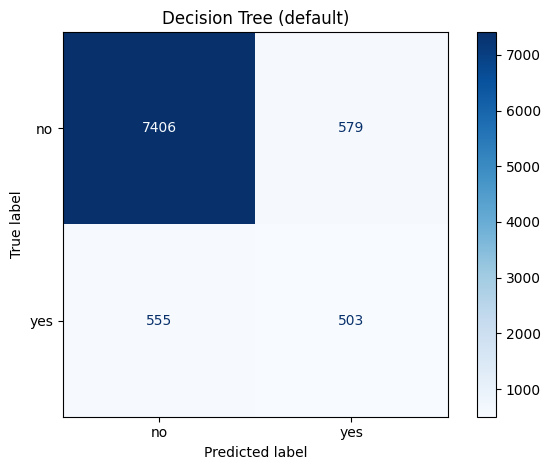

In [26]:
# Pipeline: Chains preprocessing and model fitting sequentially.
# DecisionTreeClassifier: Initializes the classification tree.
# - random_state=RANDOM_STATE: Ensures consistent tree splits on multiple runs.
tree_default = Pipeline([("prep", prep_tree),
                         ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE))])

# .fit(): Fits the entire pipeline on the training features (X_train) and labels (y_train).
# This trains the one-hot encoder and finds decision tree splits sequentially.
tree_default.fit(X_train, y_train)

name = "Decision Tree (default)"
row, cm, y_pred = evaluate(name, tree_default, X_test, y_test)

clf = tree_default.named_steps["clf"]
# get_depth(): Returns the maximum depth of the tree.
# get_n_leaves(): Returns the total number of terminal leaf nodes.
print(f"Tree depth: {clf.get_depth()} | leaves: {clf.get_n_leaves():,}")

# .score(): Returns the mean accuracy on the given test/train data and labels.
print(f"Train accuracy: {tree_default.score(X_train, y_train):.4f}")
print(f"Test  accuracy: {row['Accuracy']:.4f}\n")

display(pd.DataFrame([row], index=[name]).round(4))

# classification_report: Calculates main classification metrics (precision, recall, f1, support) for each class.
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4))

plot_cm(cm, name)
plt.tight_layout()
plt.show()

**Reading the result:** the unpruned tree memorises the training set (train accuracy = 100%) but reaches only about 87% on the test set — slightly *below* the 88.3% you would get by always predicting "no". It finds about half of the *yes* clients (recall ≈ 0.48), but roughly half of its *yes* predictions are wrong (precision ≈ 0.46). This is a classic case of **overfitting**.

### 2.2 Which features does the tree use?

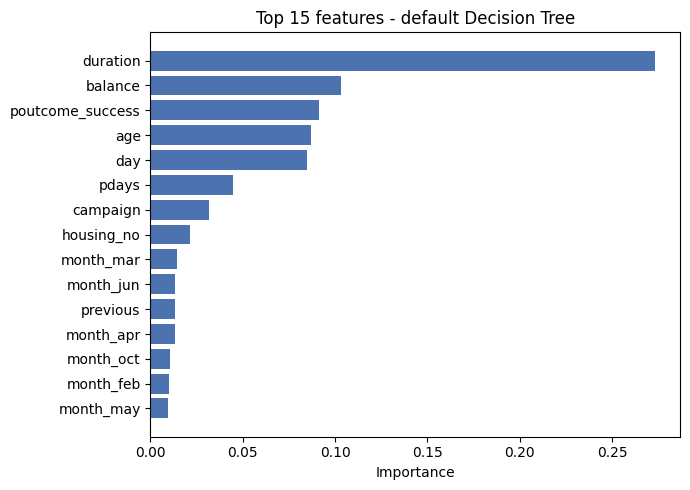

In [27]:
# get_feature_names_out: Retrieves feature names from preprocessing transformers.
feature_names = pd.Index(tree_default.named_steps["prep"].get_feature_names_out()).str.replace(r"^(num|cat)__", "", regex=True)

# feature_importances_: Array containing the computed relative importance of each feature in splitting nodes.
importance = pd.Series(clf.feature_importances_, index=feature_names).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(importance.index[::-1], importance.values[::-1], color="#4c72b0")
ax.set_xlabel("Importance")
ax.set_title("Top 15 features - default Decision Tree")
plt.tight_layout()
plt.show()

### 2.3 Controlling overfitting with `max_depth`
Limiting the depth makes the tree simpler. The depth is chosen with **5-fold cross-validation on the training set only** (scored by F1 of the *yes* class, since accuracy is dominated by the majority class), so the test set stays untouched until the final evaluation.

In [28]:
depths = [2, 3, 4, 5, 6, 8, 10, 15, 20, None]
# StratifiedKFold: Stratified K-Folds cross-validator.
# - n_splits=5: Splitting the training set into 5 folds.
# - shuffle=True: Shuffles the data prior to splitting.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []
for d in depths:
    model = Pipeline([("prep", prep_tree),
                      ("clf", DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE))])

    # cross_val_score: Automatically runs cross-validation folds and extracts metrics.
    # - scoring="f1": Computes the F1-score of the positive class for each fold.
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1")
    cv_rows.append({"max_depth": "None" if d is None else d,
                    "CV F1 (mean)": scores.mean(), "CV F1 (std)": scores.std()})

cv_df = pd.DataFrame(cv_rows)
best_depth = depths[cv_df["CV F1 (mean)"].idxmax()]

display(cv_df.round(4))
print("Best max_depth by CV F1:", best_depth)

,max_depth,CV F1 (mean),CV F1 (std)
0,2,0.4451,0.0134
1,3,0.4265,0.0222
2,4,0.4272,0.0232
3,5,0.4492,0.0137
4,6,0.4758,0.0225
5,8,0.4850,0.0262
6,10,0.4776,0.0124
7,15,0.4915,0.0111
8,20,0.4836,0.0077
9,None,0.4739,0.0060


Best max_depth by CV F1: 15


Train accuracy: 0.9605
Test  accuracy: 0.8934



,Accuracy,Precision,Recall,F1-score,TN,FP,FN,TP
Decision Tree (max_depth=15),0.8934,0.5553,0.4461,0.4948,7607,378,586,472


              precision    recall  f1-score   support

          no     0.9285    0.9527    0.9404      7985
         yes     0.5553    0.4461    0.4948      1058

    accuracy                         0.8934      9043
   macro avg     0.7419    0.6994    0.7176      9043
weighted avg     0.8848    0.8934    0.8883      9043



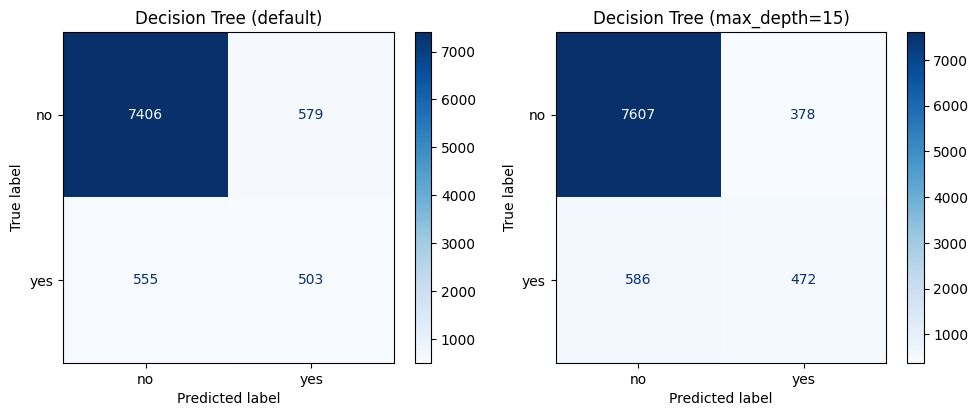

In [29]:
# Re-instantiate the pipeline with the optimized depth hyperparameter discovered during CV.
tree_tuned = Pipeline([("prep", prep_tree),
                       ("clf", DecisionTreeClassifier(max_depth=best_depth, random_state=RANDOM_STATE))])

# Fit the final tuned model on the entire training set
tree_tuned.fit(X_train, y_train)

name = f"Decision Tree (max_depth={best_depth})"
row, cm, y_pred = evaluate(name, tree_tuned, X_test, y_test)

print(f"Train accuracy: {tree_tuned.score(X_train, y_train):.4f}")
print(f"Test  accuracy: {row['Accuracy']:.4f}\n")

display(pd.DataFrame([row], index=[name]).round(4))
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_cm(conf_mats["Decision Tree (default)"], "Decision Tree (default)", ax=axes[0])
plot_cm(cm, name, ax=axes[1])
plt.tight_layout()
plt.show()

**Tuned vs. default tree:** limiting the depth raises accuracy and precision (fewer false alarms) at the cost of a slightly lower recall, and gives the better F1. The CV scores for the deeper settings (roughly 6 to 20) are close to each other, so the exact "best" depth is not sharply defined — what matters is that some depth limit beats the fully grown tree.

---
## 3. K-NN and Weighted K-NN (K = 1, 3, 5)

* **K-NN (uniform):** the K nearest training points each get **one equal vote**.
* **Weighted K-NN:** each neighbour's vote is weighted by **1 / distance**, so closer neighbours count more (`weights="distance"` in scikit-learn).
* Distance is Euclidean on the standardised + one-hot features from the preprocessing step above.

Both variants are trained and evaluated for K = 1, 3 and 5.

In [30]:
k_values = [1, 3, 5]
variants = [("K-NN", "uniform"), ("Weighted K-NN", "distance")]
metric_cols = ["Accuracy", "Precision", "Recall", "F1-score"]

knn_rows, knn_cms = [], {}
for label, weights in variants:
    for k in k_values:
        # KNeighborsClassifier: Distance-based classifier algorithm.
        # - n_neighbors=k: Number of nearest neighbors to look at.
        # - weights=weights: 'uniform' (all neighbors vote equally) or 'distance' (weight reciprocal of distance).
        model = Pipeline([("prep", prep_knn),
                          ("clf", KNeighborsClassifier(n_neighbors=k, weights=weights))])

        # Train the preprocessing pipeline and KNN on train set
        model.fit(X_train, y_train)
        name = f"{label} (K={k})"

        # Custom evaluation helper (internally evaluates metrics and saves outputs)
        row, cm, _ = evaluate(name, model, X_test, y_test)
        knn_rows.append({"Method": label, "K": k, **row})
        knn_cms[(label, k)] = cm

knn_df = pd.DataFrame(knn_rows)
display(knn_df.round(4))

,Method,K,Accuracy,Precision,Recall,F1-score,TN,FP,FN,TP
0,K-NN,1,0.8812,0.4914,0.4329,0.4603,7511,474,600,458
1,K-NN,3,0.8947,0.5796,0.3648,0.4478,7705,280,672,386
2,K-NN,5,0.8962,0.5990,0.3403,0.4340,7744,241,698,360
3,Weighted K-NN,1,0.8812,0.4914,0.4329,0.4603,7511,474,600,458
4,Weighted K-NN,3,0.8940,0.5729,0.3677,0.4479,7695,290,669,389
5,Weighted K-NN,5,0.8965,0.5993,0.3478,0.4402,7739,246,690,368


### 3.1 Confusion matrices
Top row: K-NN (uniform votes). Bottom row: Weighted K-NN (distance-weighted votes).

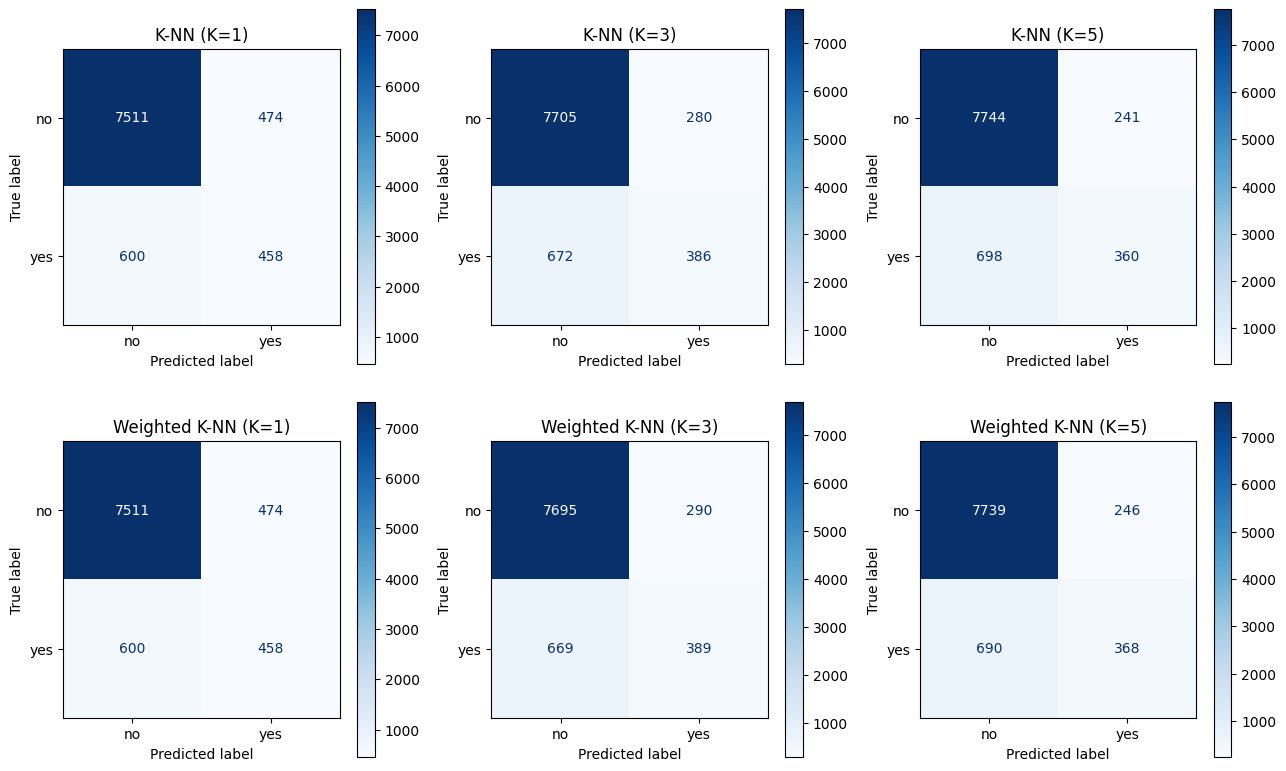

In [31]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for r, (label, _) in enumerate(variants):
    for c, k in enumerate(k_values):
        plot_cm(knn_cms[(label, k)], f"{label} (K={k})", ax=axes[r, c])
plt.tight_layout()
plt.show()

### 3.2 Metrics vs. K

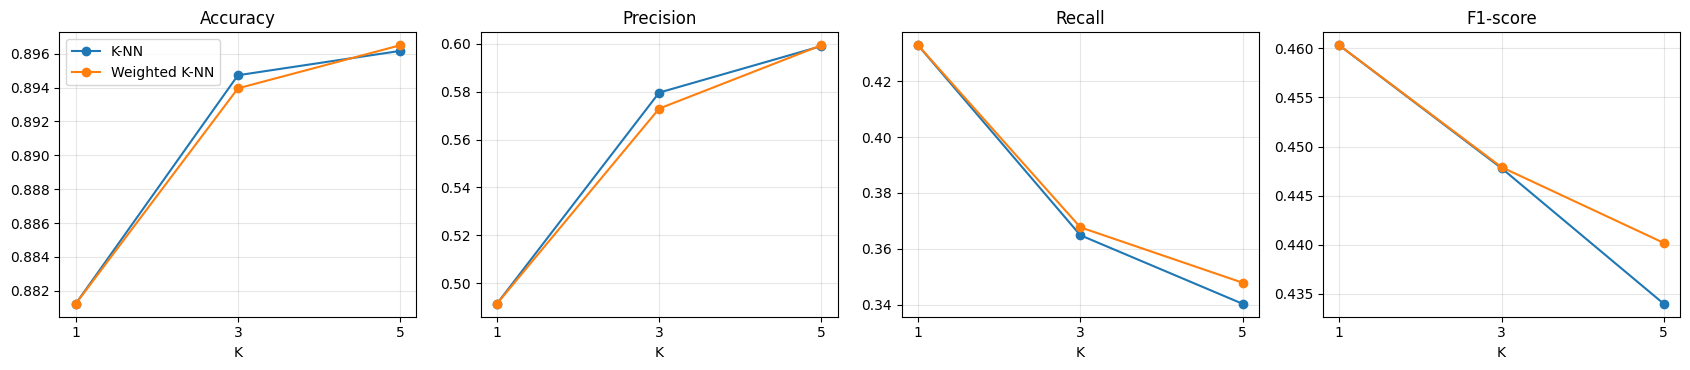

In [32]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, m in zip(axes, metric_cols):
    for label, _ in variants:
        sub = knn_df[knn_df["Method"] == label]
        ax.plot(sub["K"], sub[m], marker="o", label=label)
    ax.set_xticks(k_values)
    ax.set_xlabel("K")
    ax.set_title(m)
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()

In [33]:
# Direct side-by-side comparison: Weighted K-NN minus plain K-NN (positive = weighting helps)
wide = knn_df.pivot(index="K", columns="Method", values=metric_cols)
diff = pd.DataFrame({m: wide[m]["Weighted K-NN"] - wide[m]["K-NN"] for m in metric_cols})
print("Weighted K-NN minus K-NN:")
display(diff.round(4))

Weighted K-NN minus K-NN:


,Accuracy,Precision,Recall,F1-score
K,,,,
1,0.0000,0.0000,0.0000,0.0000
3,-0.0008,-0.0067,0.0028,0.0001
5,0.0003,0.0003,0.0076,0.0062


---
## 4. Overall comparison

In [34]:
summary = pd.DataFrame(results).T
summary[["TN", "FP", "FN", "TP"]] = summary[["TN", "FP", "FN", "TP"]].astype(int)
summary[metric_cols] = summary[metric_cols].astype(float).round(4)
display(summary)

print("Best model by F1-score :", summary["F1-score"].astype(float).idxmax())
print("Best model by accuracy :", summary["Accuracy"].astype(float).idxmax())
print("Best model by recall   :", summary["Recall"].astype(float).idxmax())

,Accuracy,Precision,Recall,F1-score,TN,FP,FN,TP
Decision Tree (default),0.8746,0.4649,0.4754,0.4701,7406,579,555,503
Decision Tree (max_depth=15),0.8934,0.5553,0.4461,0.4948,7607,378,586,472
K-NN (K=1),0.8812,0.4914,0.4329,0.4603,7511,474,600,458
K-NN (K=3),0.8947,0.5796,0.3648,0.4478,7705,280,672,386
K-NN (K=5),0.8962,0.5990,0.3403,0.4340,7744,241,698,360
Weighted K-NN (K=1),0.8812,0.4914,0.4329,0.4603,7511,474,600,458
Weighted K-NN (K=3),0.8940,0.5729,0.3677,0.4479,7695,290,669,389
Weighted K-NN (K=5),0.8965,0.5993,0.3478,0.4402,7739,246,690,368


Best model by F1-score : Decision Tree (max_depth=15)
Best model by accuracy : Weighted K-NN (K=5)
Best model by recall   : Decision Tree (default)


### Conclusions (this run: `random_state=42`, `duration` kept)

* **Best overall by F1: the depth-limited Decision Tree** (F1 ≈ 0.49, precision ≈ 0.56, recall ≈ 0.45). The fully grown tree overfits (100% train vs. ≈ 87% test accuracy) and has the highest recall but low precision.
* **Effect of K in K-NN:** going from K = 1 to K = 5, accuracy and precision rise (≈ 0.88 → 0.90 and ≈ 0.49 → 0.60) while recall and F1 fall (≈ 0.43 → 0.34 and ≈ 0.46 → 0.43). Larger K smooths out noise and predicts *yes* less often: fewer false alarms, but more subscribers missed. K = 1 reacts to single (possibly noisy) neighbours, finds the most *yes* clients and gives the best K-NN F1, but with many false positives.
* **Weighted vs. plain K-NN:** for K = 1 they are identical — with one neighbour its weight cannot change the vote. For K = 3 and 5 the differences are below one percentage point (about 8 clients out of 1,058 subscribers at K = 5), so distance weighting makes no meaningful difference on this dataset.
* **Decision Tree vs. K-NN:** the best tree beats every K-NN variant on F1. K-NN at K = 5 gets slightly higher accuracy and precision but misses about two thirds of the subscribers. The tree is also cheaper at prediction time and interpretable (`duration`, `balance`, `poutcome_success` are its top features), while K-NN needs scaled inputs and must keep the whole training set.
* **Accuracy is not enough here:** every model scores between roughly 87% and 90%, around the 88.3% of always answering "no". Every model also finds fewer than half of the real subscribers (recall ≤ 0.48), because *yes* is the rare class and default decision rules favour *no*.
* **Ideas to improve (beyond this lab):** `class_weight="balanced"` or threshold tuning for the tree, a wider search over K and distance metrics, and re-running with `DROP_DURATION = True` for a model that could be used before a call is made.